$$\LARGE \ Упражнение \ по \ программированию \ 1: \ Линейная \ регрессия $$
$$\large Машинное \ обучение $$

# 1 Простая функция в Octave

Первая часть `ex1.m` знакомит вас с синтаксисом Octave и процессом отправки домашних заданий. В файле `warmUpExercise.m` вы найдёте заготовку функции Octave. Измените её так, чтобы она возвращала единичную матрицу размером 5 x 5, дописав следующий код:
$$ В \ Octave  \ функция \ eye(n) \ создает \ единичную \ матрицу \ размером \ n \times n $$


In [ ]:
cd('resources/4-lab'); # Перехожу в директорию с файлами, для более удобной работы в дальнейшем

In [ ]:
warmUpExercise()

# 2 Линейная регрессия с одной переменной

В этой части упражнения вы реализуете линейную регрессию с одной переменной для прогнозирования прибыли фургона с едой (фудтрака). Предположим, вы — генеральный директор франшизы ресторанов и рассматриваете разные города для открытия новой точки. У сети уже есть фудтраки в различных городах, и у вас есть данные о прибыли и численности населения в этих городах.

Вы хотите использовать эти данные, чтобы выбрать город для следующего расширения.

Файл `ex1data1.txt` содержит набор данных для нашей задачи линейной регрессии. Первый столбец — это численность населения города, а второй столбец — прибыль фудтрака в этом городе. Отрицательное значение прибыли означает убыток.

Скрипт `ex1.m` уже настроен так, чтобы загрузить эти данные за вас.

# 2.1 Визуализация данных

Перед началом любой задачи часто полезно разобраться в данных, визуализировав их. Для этого набора данных можно использовать точечную диаграмму (scatter plot), так как для построения графика есть всего два свойства (прибыль и численность населения). (Многие другие задачи, с которыми вы столкнётесь в реальной жизни, многомерны и не могут быть отображены на двумерном графике.)

В `ex1.m` набор данных загружается из файла данных в переменные `X` и `y`:

```octave
data = load('ex1data1.txt'); % чтение данных, разделённых запятыми
X = data(:, 1); y = data(:, 2);
m = length(y); % количество обучающих примеров

```

Далее скрипт вызывает функцию `plotData`, чтобы построить точечную диаграмму данных. Ваша задача — дописать `plotData.m` для отрисовки графика; измените файл и впишите следующий код:

```octave
plot(x, y, 'rx', 'MarkerSize', 10); % Построение графика данных
ylabel('Profit in $10,000s'); % Подпись оси Y
xlabel('Population of City in 10,000s'); % Подпись оси X

```

Теперь, когда вы продолжите запускать `ex1.m`, итоговый результат должен выглядеть как на Рисунке 1 — с такими же красными маркерами «x» и подписями осей.

Чтобы узнать больше о команде `plot`, вы можете ввести `help plot` в командной строке Octave или поискать документацию по построению графиков в интернете. (Чтобы изменить маркеры на красные «x», мы использовали опцию `'rx'` вместе с командой `plot`, то есть `plot(..,[ваши опции здесь],.., 'rx');` )

In [ ]:
data = load('ex1data1.txt'); % read comma separated data
X = data(:, 1); y = data(:, 2);
m = length(y); % number of training examples

plotData(X, y)

# 2.2 Градиентный спуск

В этой части вы подберёте параметры линейной регрессии $\theta$ для нашего набора данных с помощью градиентного спуска.

# 2.2.1 Уравнения обновления

Цель линейной регрессии — минимизировать функцию стоимости


$$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2$$


где гипотеза $h_\theta(x)$ задаётся линейной моделью


$$h_\theta(x) = \theta^T x = \theta_0 + \theta_1 x_1$$


Напомним, что параметры вашей модели — это значения $\theta_j$. Это те значения, которые вы будете изменять, чтобы минимизировать стоимость $J(\theta)$. Один из способов сделать это — использовать алгоритм пакетного градиентного спуска (batch gradient descent). В пакетном градиентном спуске на каждой итерации выполняется обновление

$$\theta_j := \theta_j - \alpha \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)} \ \ \  (\text{одновременное обновление } \theta_j \text{ для всех } j).$$

С каждым шагом градиентного спуска ваши параметры $\theta_j$ приближаются к оптимальным значениям, при которых достигается наименьшая стоимость $J(\theta)$.

```
Примечание по реализации: В Octave мы храним каждый пример в виде строки матрицы X. Чтобы учесть свободный член (θ0), мы добавляем дополнительный первый столбец в X и заполняем его единицами. Это позволяет рассматривать θ0 просто как ещё один «признак».

```

# 2.2.2 Реализация

В `ex1.m` мы уже подготовили данные для линейной регрессии. В следующих строках мы добавляем ещё одно измерение к нашим данным, чтобы учесть свободный член $\theta_0$. Мы также инициализируем начальные параметры нулями и задаём скорость обучения `alpha` равной `0.01`.

In [ ]:
X = [ones(m, 1), data(:,1)]; % Add a column of ones to x
theta = zeros(2, 1); % initialize fitting parameters
iterations = 1500;
alpha = 0.01;

# 2.2.3 Вычисление функции стоимости $J(\theta)$

Когда вы выполняете градиентный спуск для минимизации функции стоимости $J(\theta)$, полезно отслеживать сходимость, вычисляя стоимость. В этом разделе вы реализуете функцию для расчёта $J(\theta)$, чтобы проверять сходимость вашей реализации градиентного спуска.

Ваша следующая задача — дописать код в файле `computeCost.m`, который представляет собой функцию, вычисляющую $J(\theta)$. При этом помните, что переменные `X` и `y` — не скалярные значения, а матрицы, строки которых представляют примеры из обучающей выборки.

После того как вы завершите функцию, на следующем шаге `ex1.m` запустит `computeCost` один раз с параметром $\theta$, инициализированным нулями, и вы увидите выведенное на экран значение стоимости.

Ожидаемое значение стоимости — `32.07`.

Теперь вам следует отправить «compute cost» для линейной регрессии с одной переменной.

In [ ]:
computeCost(X, y, theta)

# 2.2.4 Градиентный спуск

Далее вы реализуете градиентный спуск в файле `gradientDescent.m`.
Структура цикла уже написана за вас, и вам нужно лишь добавить обновление $\theta$ на каждой итерации.
Во время программирования убедитесь, что вы понимаете, что именно вы пытаетесь оптимизировать и что обновляется. Помните, что стоимость $J(\theta)$ параметризована вектором $\theta$, а не `X` и `y`. То есть мы минимизируем значение $J(\theta)$,

изменяя значения вектора $\theta$, а не изменяя `X` или `y`. Обратитесь к уравнениям в этом руководстве и к видеолекциям, если вы не уверены.
Хороший способ проверить, что градиентный спуск работает правильно, — посмотреть на значение $J(\theta)$ и убедиться, что оно уменьшается с каждым шагом. Стартовый код для `gradientDescent.m` вызывает `computeCost` на каждой итерации и выводит значение стоимости. Если вы правильно реализовали градиентный спуск и `computeCost`, ваше значение $J(\theta)$ никогда не должно увеличиваться и должно сойтись к устойчивому значению к концу работы алгоритма.

После завершения `ex1.m` использует ваши итоговые параметры для построения линии регрессии. Результат должен выглядеть примерно как на Рисунке 2:

Ваши итоговые значения $\theta$ также будут использованы для прогнозирования прибыли в районах с населением 35 000 и 70 000 человек. Обратите внимание, как следующие строки в `ex1.m` используют матричное умножение вместо явного суммирования или циклов для вычисления прогнозов. Это пример векторизации кода в Octave.

Теперь вам следует отправить градиентный спуск для линейной регрессии с одной переменной.

```octave
predict1 = [1, 3.5] * theta;
predict2 = [1, 7] * theta;


```

In [ ]:
theta = zeros(2, 1);
fprintf("Koefficients: ")
theta = gradientDescent(X, y, theta, alpha, iterations)

plotData(X(:, 2), y);
hold on;
plot(X(:, 2), X * theta, '-');
legend('Train data', 'Linear regression');
hold off;

predict1 = [1, 3.5] * theta;
fprintf('For 35_000: profit = %f \n', predict1 * 10000);

predict2 = [1, 7] * theta;
fprintf('For 70_000: profit = %f \n', predict2 * 10000);


# 2.3 Отладка

Вот несколько моментов, которые стоит учитывать при реализации градиентного спуска:

* Индексы массивов в Octave начинаются с единицы, а не с нуля. Если вы храните $\theta_0$ и $\theta_1$ в векторе `theta`, эти значения будут находиться в `theta(1)` и `theta(2)`.

* Если вы видите много ошибок во время выполнения, проверьте ваши матричные операции, чтобы убедиться, что вы складываете и перемножаете матрицы совместимых размерностей. Вывод размерностей переменных с помощью команды `size` поможет вам в отладке.
* По умолчанию Octave воспринимает математические операторы как матричные. Это частый источник ошибок несовместимости размеров. Если вам нужно не матричное умножение, необходимо добавить «точку» (dot notation), чтобы указать это Octave. Например, `A*B` выполняет матричное умножение, а `A.*B` — поэлементное умножение.

# 2.4 Визуализация $J(\theta)$

Чтобы лучше понять функцию стоимости $J(\theta)$, теперь вы построите график стоимости по двумерной сетке значений $\theta_0$ и $\theta_1$. В этой части вам не нужно писать новый код, но важно понимать, как уже написанный вами код создаёт эти изображения.
На следующем шаге `ex1.m` уже предусмотрен код, который вычисляет $J(\theta)$ по сетке значений с помощью написанной вами функции `computeCost`.



``` octave
% initialize J vals to a matrix of 0's
8
J vals = zeros(length(theta0 vals), length(theta1 vals));
% Fill out J vals
for i = 1:length(theta0 vals)
for j = 1:length(theta1 vals)
t = [theta0 vals(i); theta1 vals(j)];
J vals(i,j) = computeCost(x, y, t);
end
end
``` 
После выполнения этих строк у вас будет двумерный массив значений $J(\theta)$. Скрипт ex1.m затем использует эти значения для построения графиков поверхности и линий уровня (surface и contour plots) функции $J(\theta)$ с помощью команд surf и contour. Графики должны выглядеть примерно как на Рисунке 3:

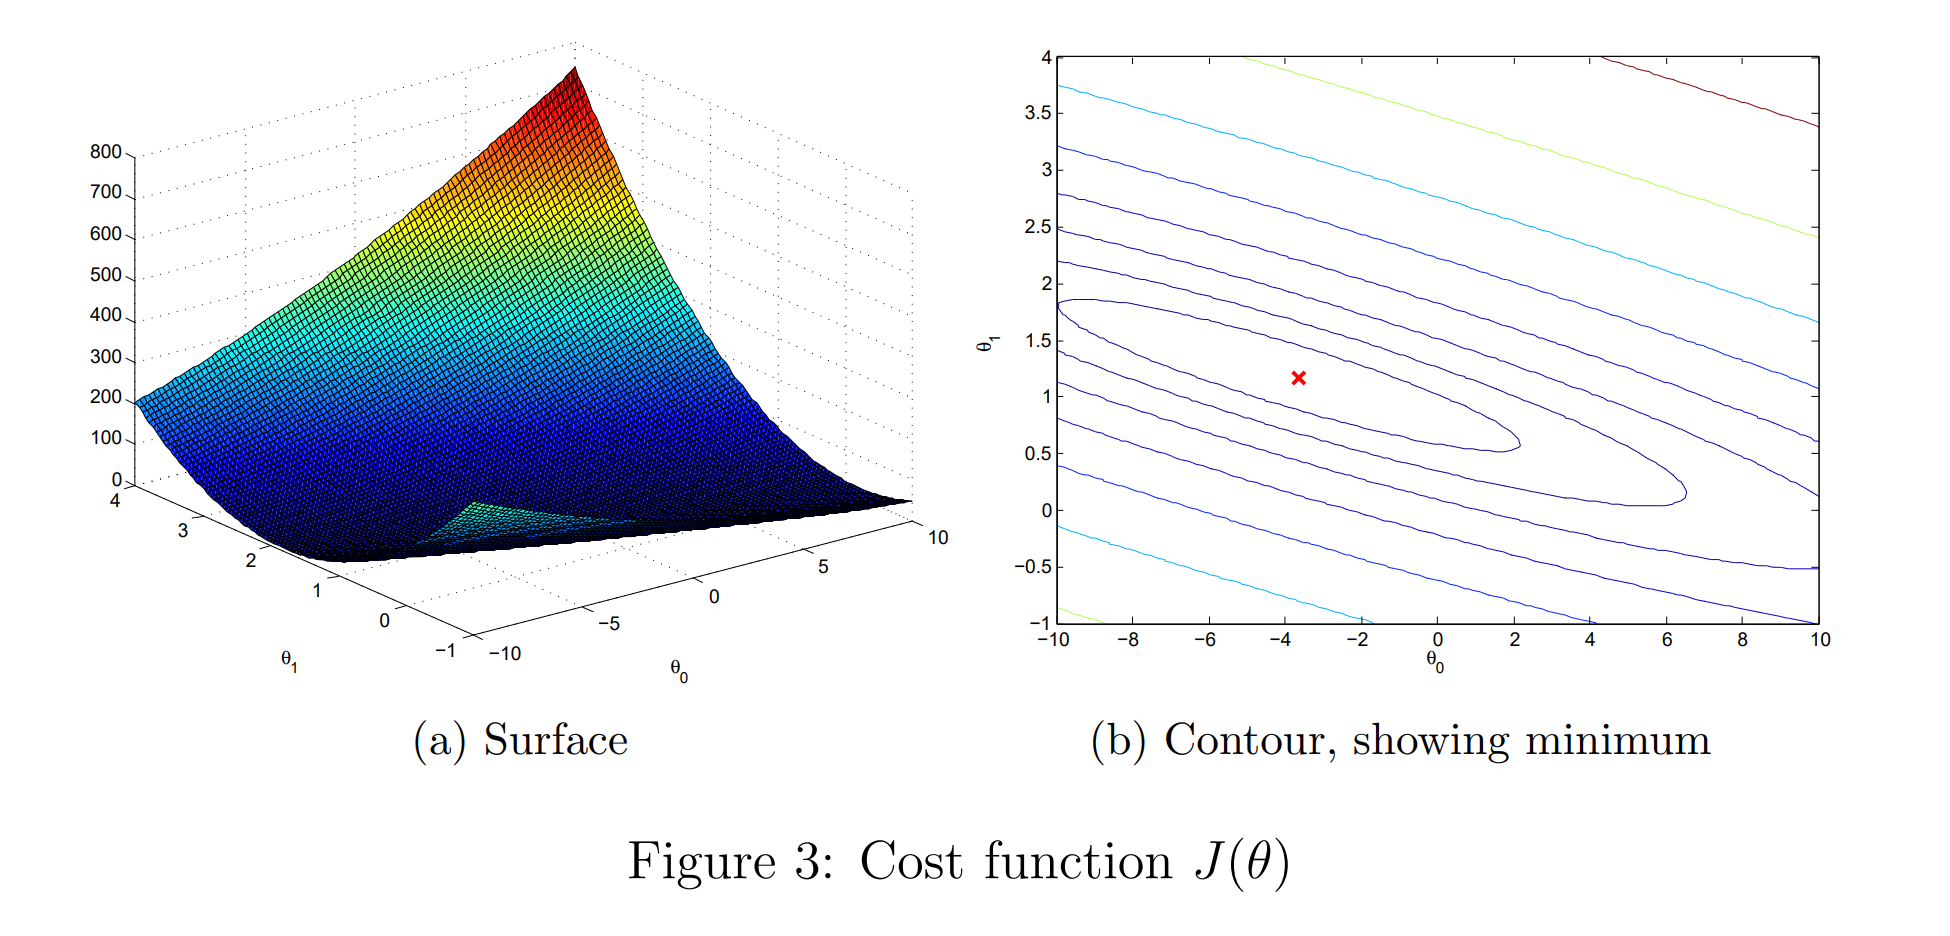

Цель этих графиков — показать, как $J(\theta)$ изменяется при изменении $\theta_0$ и $\theta_1$. Функция стоимости $J(\theta)$ имеет форму чаши и обладает глобальным минимумом (это легче увидеть на графике линий уровня, чем на трёхмерном графике поверхности). Этот минимум — оптимальная точка для $\theta_0$ и $\theta_1$, и каждый шаг градиентного спуска приближает к этой точке.

In [ ]:
ex1()

# Дополнительные упражнения (необязательно)
Если вы успешно освоили материал выше, поздравляем! Теперь вы понимаете линейную регрессию и сможете начать применять её на собственных наборах данных.

В оставшейся части этого упражнения по программированию мы включили следующие необязательные дополнительные упражнения. Они помогут вам глубже разобраться в материале, и если у вас получится их выполнить, мы настоятельно рекомендуем сделать и их тоже.

# 3 Линейная регрессия с несколькими переменными
В этой части вы реализуете линейную регрессию с несколькими переменными для прогнозирования цен на дома. Предположим, вы продаёте свой дом и хотите узнать, какая рыночная цена была бы для него подходящей. Один из способов сделать это — сначала собрать информацию о недавно проданных домах и построить модель цен на жильё.
Файл `ex1data2.txt` содержит обучающую выборку цен на дома в Портленде, штат Орегон. Первый столбец — это площадь дома (в квадратных футах), второй столбец — количество спален, а третий столбец — цена дома.
Скрипт `ex1_multi.m` уже подготовлен, чтобы помочь вам пошагово выполнить это упражнение.

In [ ]:
ex1_multi


# 3.1 Нормализация признаков
Скрипт ex1 multi.m начнёт с загрузки и вывода нескольких значений из этого датасета. Посмотрев на значения, заметьте, что площади домов примерно в 1000 раз больше числа спален. Когда признаки различаются на порядки, предварительное масштабирование признаков позволяет градиентному спуску сходиться гораздо быстрее.
Ваша задача здесь — дописать код в featureNormalize.m:
- Вычесть из датасета среднее значение каждого признака.
- После вычитания среднего дополнительно отмасштабировать (разделить) значения признаков на их соответствующие «стандартные отклонения».


Стандартное отклонение — это способ измерить разброс в диапазоне значений конкретного признака (большинство точек данных будут лежать в пределах ±2 стандартных отклонений от среднего); это альтернатива вычислению размаха значений (max-min). В Octave для вычисления стандартного отклонения можно использовать функцию «std». Например, внутри featureNormalize.m величина X(:,1) содержит все значения x1 (площади домов) в обучающей выборке, поэтому std(X(:,1)) вычисляет стандартное отклонение площадей домов.\
На момент вызова featureNormalize.m дополнительный столбец из единиц, соответствующий x0 = 1, ещё не добавлен в X (подробности см. в ex1 multi.m).\
Сделайте это для всех признаков, и ваш код должен работать с датасетами любого размера (с любым числом признаков и примеров). Учтите, что каждый столбец матрицы X соответствует одному признаку.
Теперь вы можете отправить решение по нормализации признаков.
```
Примечание по реализации: при нормализации признаков важно сохранять значения, использованные для нормализации — среднее значение и стандартное отклонение, по которым велись расчёты. После обучения параметров модели мы часто хотим предсказать цены домов, которых раньше не видели. Получив новое значение x (площадь гостиной и число спален), мы должны сначала нормализовать x, используя среднее и стандартное отклонение, вычисленные ранее на обучающей выборке.
```

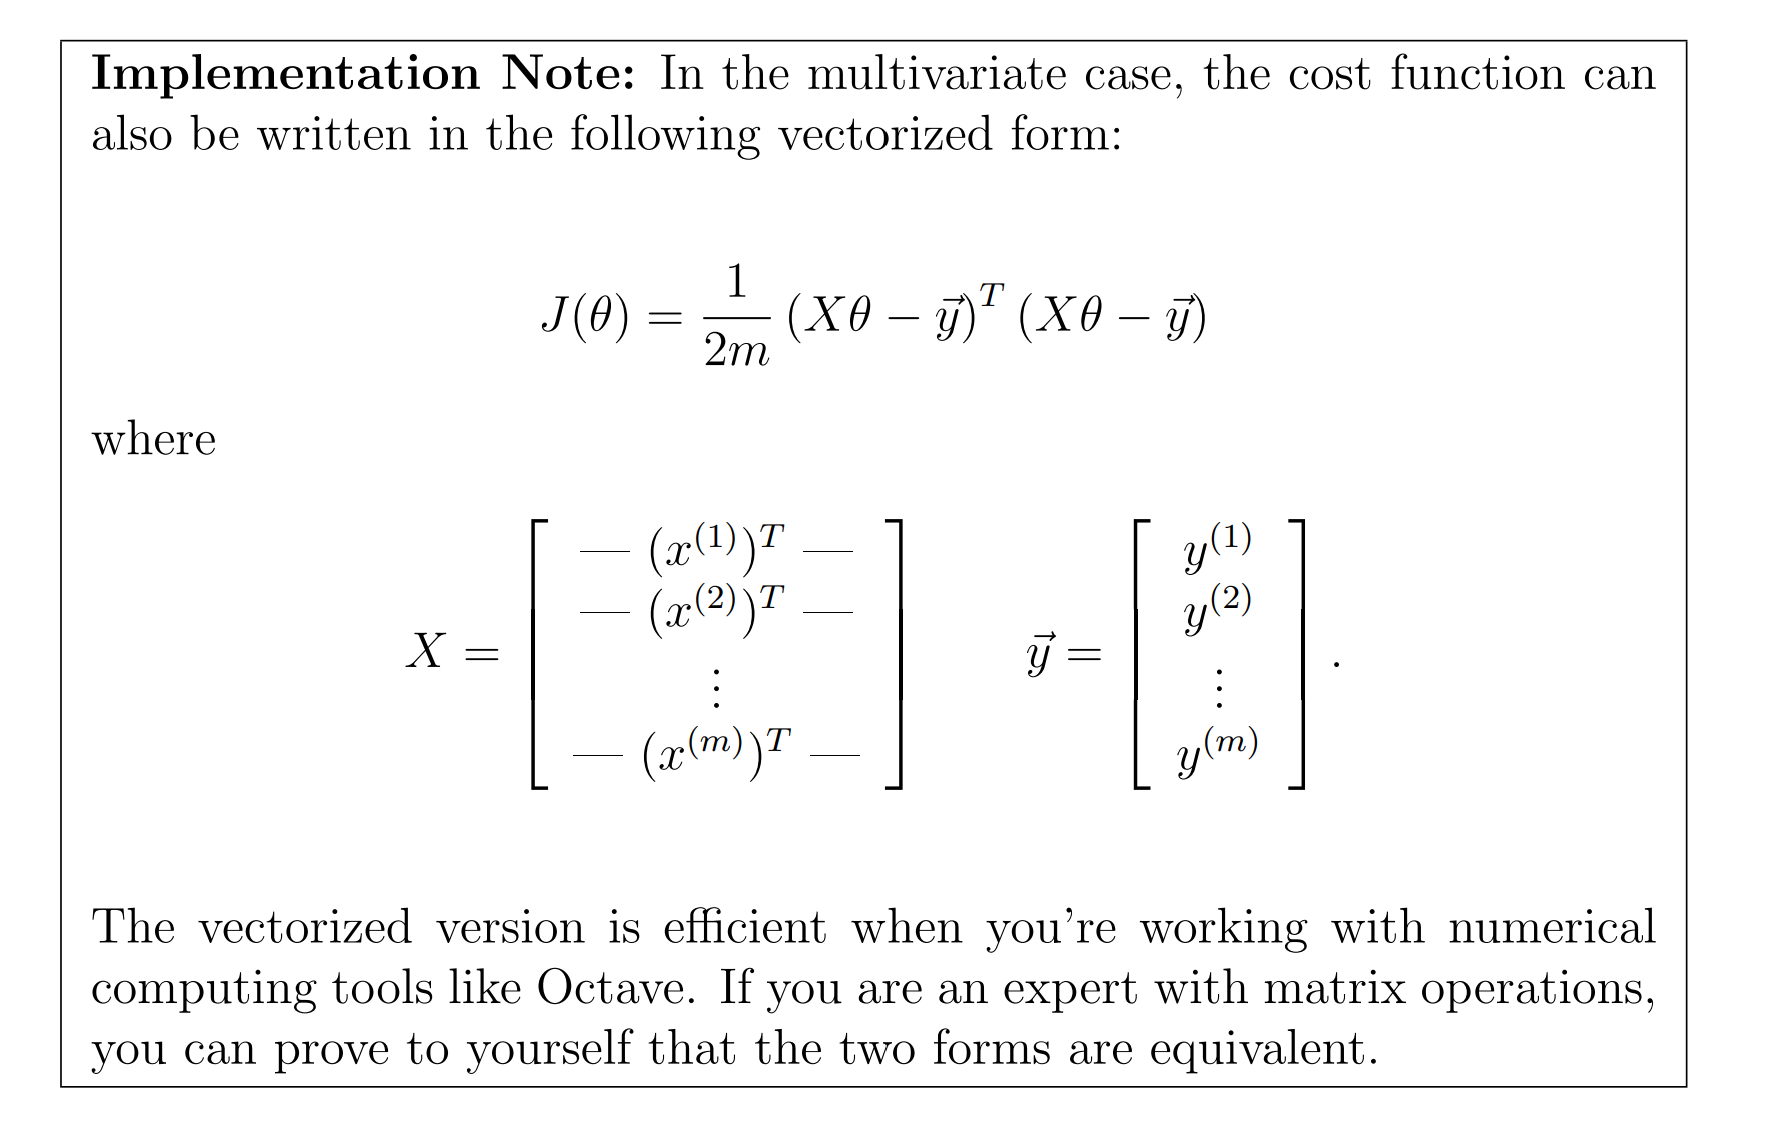

# 3.2.1 Необязательное упражнение (без оценки): Выбор скорости обучения

В этой части упражнения вы сможете опробовать разные скорости обучения для датасета и подобрать такую, при которой модель сходится быстро. Изменить скорость обучения можно, отредактировав `ex1_multi.m` и поменяв участок кода, задающий скорость обучения.


На следующем этапе `ex1_multi.m` вызовет вашу функцию `gradientDescent.m` и запустит градиентный спуск примерно на 50 итераций с выбранной скоростью обучения. Функция также должна вернуть историю значений $J(\theta)$ в векторе `J`. После последней итерации скрипт `ex1_multi.m` строит график значений `J` в зависимости от номера итерации.


Если вы выбрали скорость обучения в удачном диапазоне, ваш график будет выглядеть примерно как на рисунке 4. Если график выглядит совсем иначе — особенно если значение $J(\theta)$ растёт или вовсе «взрывается» (уходит в бесконечность/огромные числа), подберите другую скорость обучения и попробуйте снова. Мы рекомендуем перебирать значения скорости обучения $\alpha$ по логарифмической шкале с мультипликативным шагом примерно в 3 раза от предыдущего значения (то есть `0.3`, `0.1`, `0.03`, `0.01` и так далее). Также вы можете скорректировать число итераций, если это поможет лучше увидеть общий тренд кривой.

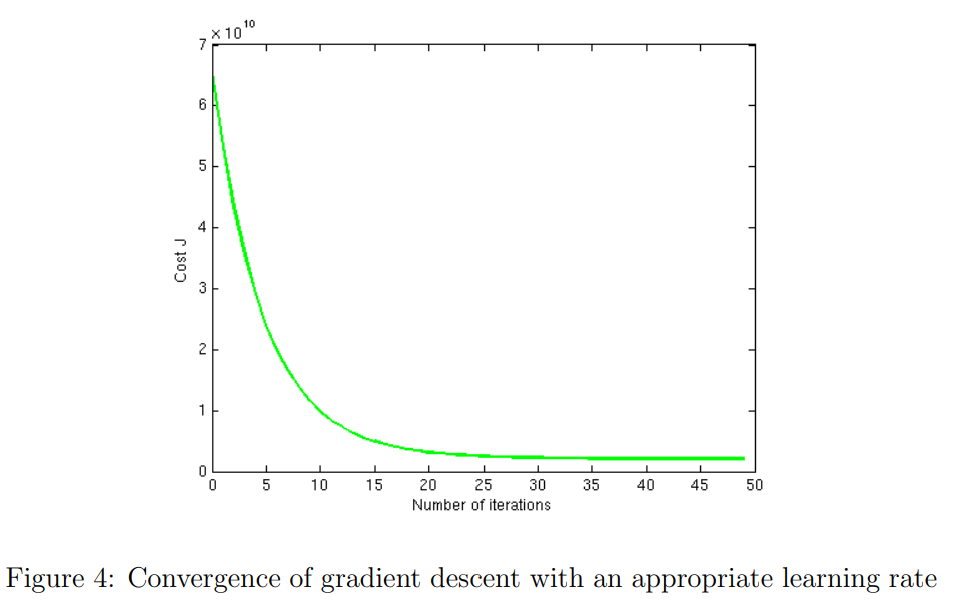

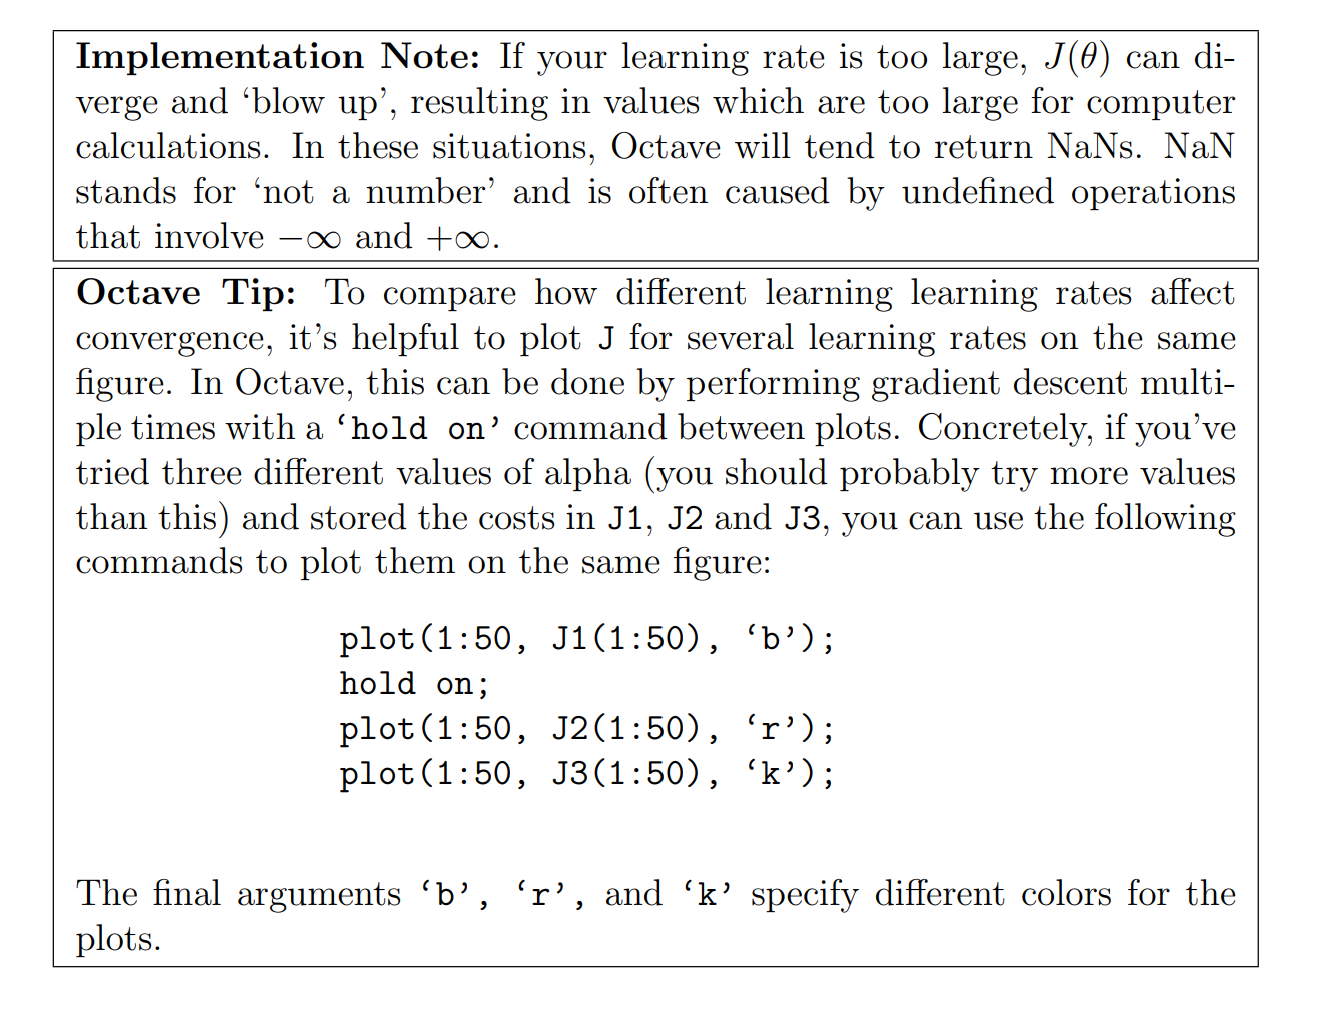

Обратите внимание на то, как меняются кривые сходимости при изменении скорости обучения. При маленькой скорости обучения вы увидите, что градиентному спуску требуется очень много времени, чтобы сойтись к оптимальному значению. И наоборот — при слишком большой скорости обучения градиентный спуск может не сойтись или даже разойтись!

Используя лучшую найденную скорость обучения, запустите скрипт `ex1_multi.m`, чтобы прогнать градиентный спуск до сходимости и получить итоговые значения $\theta$. Затем используйте это значение $\theta$, чтобы предсказать цену дома площадью 1650 квадратных футов с 3 спальнями. Это значение вы позже используете для проверки своей реализации нормальных уравнений. Не забудьте нормализовать признаки перед тем, как делать это предсказание!

Отправлять решения для этих необязательных упражнений (без оценки) не нужно.

In [ ]:
ex1_multi()

### 3.3 Нормальные уравнения

В видеолекциях вы узнали, что аналитическое решение линейной регрессии задаётся формулой:

$$\theta = (X^T X)^{-1} X^T y$$

Использование этой формулы не требует никакого масштабирования признаков, и вы получаете точное решение за одно вычисление — без «цикла до сходимости», как в градиентном спуске.

Допишите код в `normalEqn.m`, чтобы вычислить $\theta$ по приведённой выше формуле. Помните, что хотя масштабировать признаки не нужно, к матрице `X` всё равно необходимо добавить столбец единиц для свободного члена ($\theta_0$).

Теперь вы можете отправить функцию нормальных уравнений.

> **Необязательное (не оцениваемое) упражнение:** теперь, когда вы нашли $\theta$ этим методом, используйте его для предсказания цены дома площадью 1650 кв. футов с 3 спальнями. Вы должны увидеть, что получается та же предсказанная цена, что и при использовании модели, обученной градиентным спуском (в разделе 3.2.1).

In [ ]:
theta = normalEqn(X, y);
price = [1, 1650, 3] * theta;
fprintf('Predicted price (normal equations): $%f\n', price);